# GameTheory-22 : Jeux stochastiques — la valeur d'un jeu à états (Shapley, 1953)

**Navigation** : [Index](README.md) | [<< Carnet 17e — Persuasion bayésienne](GameTheory-17e-Bayesian-Persuasion-Python.ipynb) | [Version C#](GameTheory-22-Jeux-Stochastiques-Shapley-CSharp.ipynb) | [Carnet 23 — Failles légales >>](GameTheory-23-Loopholes-Fiscaux-Python-Lean.ipynb)

## Un jeu qui change d'état à chaque manche

Le carnet **Dynamics-01** a étudié des jeux *répétés* où la **même** matrice se rejoue à
l'identique. Ici, l'ingrédient nouveau : **l'état du jeu évolue d'une manche à l'autre**.

À chaque manche :
1. l'état courant $s$ est connu ;
2. les deux joueurs choisissent des actions $a$ (rang) et $b$ (colonne) ;
3. le gain de la manche $g(s,a,b)$ est versé ;
4. l'état passe à $s'$ selon une **loi de transition** $P(s'\mid s,a,b)$ qui dépend des actions.

C'est un **jeu stochastique** (Shapley, 1953). La question centrale :

> Existe-t-il une **valeur** du jeu — un nombre par état — et comment la calculer ?

### Objectifs d'apprentissage
- Formuler un jeu stochastique à deux joueurs **à somme nulle** (états, actions, gains, transitions)
- Expliquer l’existence de la **valeur** (théorème de Shapley) et l’approcher par **itération de valeur**
- **Mesurer** l'écart entre valeur statique (une manche isolée) et valeur dynamique (la partie entière), et le distinguer d'un gain de planification comme d'une valeur de l'information
- Relier au carnet **17** (multi-agent RL) : cette valeur est l'objet que le RL apprend à *approximer*

### Prerequis
- Carnet **05** (jeux à somme nulle, minimax), **Dynamics-01** (jeux répétés, théorème folk)
- `numpy`, `matplotlib`

### Durée estimée : 60 minutes

## 1. Formalisation — un jeu stochastique à somme nulle

Un jeu stochastique à somme nulle est le quintuple
$\bigl(S,\; A,\; B,\; G,\; P\bigr)$ :

| Symbole | Sens |
|---|---|
| $S$ | ensemble d'états (fini ici) |
| $A$ / $B$ | actions du joueur **rang** (maximise) / **colonne** (minimise) |
| $G[s]$ | matrice de gain de la manche à l'état $s$ ($\lvert A\rvert \times \lvert B\rvert$) |
| $P[s,a,b,\cdot]$ | loi de transition vers l'état suivant |

Avec un **facteur d'actualisation** $\gamma \in [0,1)$, la **valeur** $V : S \to \mathbb{R}$ est le
point fixe de l'opérateur de Bellman — où le $\max$ et le $\min$ portent sur des **stratégies
mixtes** ($x \in \Delta(A)$ pour le rang, $y \in \Delta(B)$ pour la colonne) :

$$V(s) = \max_{x \in \Delta(A)} \min_{y \in \Delta(B)} \Big[ (1-\gamma)\, x^{\top} G[s]\, y \;+\; \gamma \sum_{s'} \Big( \sum_{a} \sum_{b} x_a\, y_b\, P[s,a,b,s'] \Big)\, V(s') \Big]$$

Pour une paire fixée $(x, y)$, le gain de la manche est $x^{\top} G[s]\, y$ et la transition vers
$s'$ est l'espérance de $P[\cdot]$ sous la loi produit $x \otimes y$. À chaque état, le
$\max_x \min_y$ est donc un **jeu matriciel 2×2** au sens du carnet **05** (théorème de minimax) —
et non un max/min sur des actions pures : c'est exactement ce que calcule le code de la section 2.

Le **théorème de Shapley (1953)** : cet opérateur a un point fixe **unique**, et l'itération
de valeur $V_{k+1} = \mathcal{T}(V_k)$ **converge** vers lui depuis n'importe quelle initialisation.
C'est l'analogue, pour les jeux à somme nulle, de l'itération de valeur de la programmation
dynamique (MCDP) — avec un `max` **et** un `min` au lieu d'un simple `max`.


In [1]:
import numpy as np

# --- Un jeu stochastique 2 etats, 2x2 par etat, somme nulle -----------------
# Etats : 0 = "bas" (gain modeste, le rang peut y rester ou en sortir), 1 = "haut" (gain eleve)
# Actions rang a in {0,1}, actions colonne b in {0,1}
#
# Gains de la manche (le rang maximise, la colonne minimise) :
G = np.array([
    [[2., 2.],      # etat 0 : gain constant 2 -> aucun conflit myope, valeur statique 2
     [2., 2.]],
    [[6., 2.],      # etat 1 : jeu "coordination adverse", valeur statique 4
     [2., 6.]],
], dtype=float)

# Transitions P[s][a][b][s'] : la dependance aux actions du RANG decide de l'etat suivant.
#   a=0 ("rester") -> on reste ; a=1 ("sauter") -> on passe a l'etat 1 (puis absorbant).
# L'action de la COLONNE ne joue pas sur la transition (elle agit sur le gain de la manche).
P = np.zeros((2, 2, 2, 2))
for b in range(2):
    P[0, 0, b, 0] = 1.0   # etat 0, a=0  -> reste en 0
    P[0, 1, b, 1] = 1.0   # etat 0, a=1  -> saute en 1
    P[1, 0, b, 1] = 1.0   # etat 1 : absorbant (reste en 1)
    P[1, 1, b, 1] = 1.0
print("Nombre d'etats :", P.shape[0], " | actions rang :", P.shape[1], " | actions col :", P.shape[2])
print("G[0] =\n", G[0], "\nvaleur statique de G[0] = 2 (matrice constante)")
print("G[1] =\n", G[1], "\nvaleur statique de G[1] = 4 (strategie mixte p=0.5)")

Nombre d'etats : 2  | actions rang : 2  | actions col : 2
G[0] =
 [[2. 2.]
 [2. 2.]] 
valeur statique de G[0] = 2 (matrice constante)
G[1] =
 [[6. 2.]
 [2. 6.]] 
valeur statique de G[1] = 4 (strategie mixte p=0.5)


## 2. La valeur **statique** — une seule manche

Jouons la matrice de la manche $G[s]$ comme un jeu isolé, sans regarder l'état suivant : on
obtient sa **valeur minimax**, la **valeur statique** $v_{\mathrm{stat}}(s)$. C'est exactement le
contenu du carnet 05, et c'est le calcul que fait un joueur **myope**. Ce n'est pas pour autant
ce que ce joueur obtient sur toute la partie : ses actions déplacent aussi l'état, et la
section 4 l'évalue sur la partie entière. Calculons d'abord la valeur statique par les
stratégies mixtes.

In [2]:
def valeur_statique_mat(M):
    """Valeur (minimax) d'une matrice 2x2 a somme nulle + strategies d'equilibre.
    Renvoie (valeur, p_rang, q_col). Deux cas, dans l'ordre :
    1. POINT SELLE PUR (cas general) : v = max_i min_j M[i,j] = min_j max_i M[i,j]
       -> equilibre en strategies pures (ligne i*, colonne j*).
    2. AUCUN point selle : equilibre mixte plein support, formules fermees 2x2
       (la formule mixte ne s'applique QUE dans ce cas — l'appliquer a une matrice
       qui a un point selle renvoie une valeur hors des bornes de la matrice)."""
    M = np.asarray(M, dtype=float)
    v_maxmin  = float(np.max(np.min(M, axis=1)))   # le rang garantit
    v_minimax = float(np.min(np.max(M, axis=0)))   # la colonne garantit
    if abs(v_maxmin - v_minimax) < 1e-9:
        # 1. point selle pur : strategies pures
        i_star = int(np.argmax(np.min(M, axis=1)))
        j_star = int(np.argmin(np.max(M, axis=0)))
        p = np.zeros(2); p[i_star] = 1.0
        q = np.zeros(2); q[j_star] = 1.0
        return v_maxmin, p, q
    # 2. aucun point selle : equilibre mixte interieur
    a, b_ = M[0, 0], M[0, 1]
    c, d  = M[1, 0], M[1, 1]
    den = a - b_ - c + d
    v = (a * d - b_ * c) / den
    p = np.array([(d - c), (a - b_)]) / den   # proba du rang
    q = np.array([(d - b_), (a - c)]) / den   # proba de la colonne
    return float(v), p, q

# Témoin négatif (réservation adjoint, 23/10) : une matrice AVEC point selle ne se
# résout pas par la formule mixte. M a la selle (ligne 0, colonne 1, valeur 3) ;
# l'ancienne version renvoyait (6.0, [2.0, -1.0], [3.0, -2.0]) : la valeur 6.0 dépasse
# le gain maximal de la matrice (4) et les probabilités sont négatives — hors du jeu.
M_wit = np.array([[4.0, 3.0], [2.0, 0.0]])
v_wit, p_wit, q_wit = valeur_statique_mat(M_wit)
assert abs(v_wit - 3.0) < 1e-9, f"témoin négatif : valeur {v_wit} != 3.0"
assert p_wit.tolist() == [1.0, 0.0] and q_wit.tolist() == [0.0, 1.0], f"témoin négatif : p={p_wit} q={q_wit}"
print(f"Témoin négatif : M = [[4,3],[2,0]]  ->  v = {v_wit}  (point selle : ligne 0 / colonne 1)")
print(f"  p_rang = {p_wit}   q_colonne = {q_wit}")
print(f"  [l'ancienne formule mixte donnait ici (6.0, [2.0, -1.0], [3.0, -2.0]) : valeur hors des bornes, probabilités négatives]")

v0, p0, q0 = valeur_statique_mat(G[0])
v1, p1, q1 = valeur_statique_mat(G[1])
v_statique = np.array([v0, v1])
print(f"Valeur statique etat 0 = {v0:.4f}   (matrice constante : point selle, p={p0.round(3)})")
print(f"Valeur statique etat 1 = {v1:.4f}   (aucun point selle : equilibre mixte p={p1.round(3)})")
print("v_statique =", v_statique.round(4))


Témoin négatif : M = [[4,3],[2,0]]  ->  v = 3.0  (point selle : ligne 0 / colonne 1)
  p_rang = [1. 0.]   q_colonne = [0. 1.]
  [l'ancienne formule mixte donnait ici (6.0, [2.0, -1.0], [3.0, -2.0]) : valeur hors des bornes, probabilités négatives]
Valeur statique etat 0 = 2.0000   (matrice constante : point selle, p=[1. 0.])
Valeur statique etat 1 = 4.0000   (aucun point selle : equilibre mixte p=[0.5 0.5])
v_statique = [2. 4.]


## 3. La valeur dynamique — itération de valeur

La **valeur dynamique** $V$ est la valeur du jeu stochastique entier, transitions comprises. On applique l’opérateur de Bellman : à chaque état $s$, on résout le jeu matriciel dont le gain est le paiement courant normalisé plus l’espérance actualisée de la valeur suivante :

$$T(V)(s) = \text{valeur}(M_s), \qquad M_s[a,b] = (1-\gamma)G[s,a,b] + \gamma\sum_{s'}P[s,a,b,s']V(s')$$

On part de $V_0=0$ et on arrête quand la différence entre deux itérations passe sous la tolérance. Le théorème de Shapley garantit théoriquement l’unicité et la convergence vers le point fixe; l’arrêt numérique donne une approximation flottante, pas une preuve exacte.

In [3]:
def operateur_bellman(V, G, P, gamma):
    """T(V)(s) = valeur (strategies mixtes) du jeu matriciel de la manche a l'etat s :
    M_s[a,b] = (1-gamma) G[s,a,b] + gamma * (P[s,a,b] . V).
    C'est ici que le max/min pur devient un VRAI jeu matriciel (strategies mixtes,
    comme au carnet 05) : indispensable des que la matrice n'a pas de point selle."""
    S = G.shape[0]
    T = np.zeros(S)
    for s in range(S):
        M = np.zeros((G.shape[1], G.shape[2]))
        for a in range(G.shape[1]):
            for b in range(G.shape[2]):
                M[a, b] = (1 - gamma) * G[s, a, b] + gamma * (P[s, a, b] @ V)
        T[s] = valeur_statique_mat(M)[0]   # valeur 2x2 (strategies mixtes)
    return T

def valeur_iteration(G, P, gamma, V0=None, tol=1e-9, max_iter=20000):
    S = G.shape[0]
    V = np.zeros(S) if V0 is None else V0.copy()
    hist = [V.copy()]
    for k in range(max_iter):
        Vn = operateur_bellman(V, G, P, gamma)
        hist.append(Vn.copy())
        if np.max(np.abs(Vn - V)) < tol:
            V = Vn
            return V, k + 1, hist
        V = Vn
    return V, max_iter, hist

gamma = 0.9
V, iters, hist = valeur_iteration(G, P, gamma)
print(f"gamma = {gamma}")
print(f"Valeur dynamique V = {V.round(4)}   (converge en {iters} itérations)")
print(f"Formule attendue : V[0] = 2 + 2*gamma = {2 + 2*gamma:.4f} , V[1] = 4")

gamma = 0.9
Valeur dynamique V = [3.8 4. ]   (converge en 189 itérations)
Formule attendue : V[0] = 2 + 2*gamma = 3.8000 , V[1] = 4


## 4. Le contraste qui porte le carnet — écart entre valeur statique et valeur dynamique

Posons la valeur dynamique $V$ à côté de la valeur statique $v_{\mathrm{stat}}$. L’écart $V(s)-v_{\mathrm{stat}}(s)$ est la **différence entre valeur statique et valeur dynamique** : il compare la valeur d’une manche isolée à celle de la partie entière, transitions comprises.

Cet écart ne compare pas deux politiques jouées sur la même partie : $v_{\mathrm{stat}}$ est la valeur d’un jeu à une manche, $V$ celle du jeu actualisé sur un horizon infini. Ce n’est pas non plus une valeur de l’information : l’état courant est connu dans les deux calculs, et aucun signal n’est ajouté.

Etat |  v_statique  |  V dynamique  |  ecart dynamique - statique
  0   |   2.0000     |    3.8000     |   1.8000
  1   |   4.0000     |    4.0000     |   -0.0000

Lecture :
  - etat 0 : ecart = 1.8000  =  2*gamma = 1.8000  -> V(0) = (1-gamma)*2 + gamma*4, d'ou un ecart gamma*(4-2)
  - etat 1 : ecart = -0.0000  (absorbant, flux constant de valeur 4 : valeurs statique et dynamique egales)


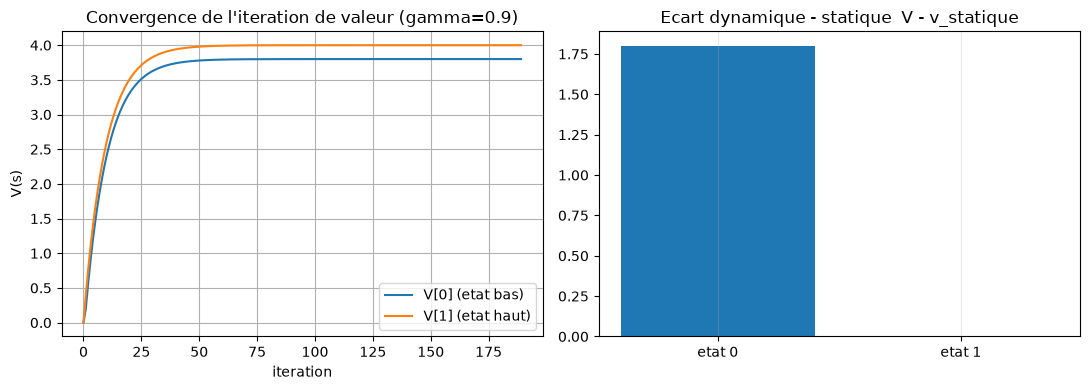

In [4]:
ecart = V - v_statique
print("Etat |  v_statique  |  V dynamique  |  ecart dynamique - statique")
for s in range(2):
    print(f"  {s}   |   {v_statique[s]:.4f}     |    {V[s]:.4f}     |   {ecart[s]:.4f}")
print(f"\nLecture :")
print(f"  - etat 0 : ecart = {ecart[0]:.4f}  =  2*gamma = {2*gamma:.4f}  -> V(0) = (1-gamma)*2 + gamma*4, d'ou un ecart gamma*(4-2)")
print(f"  - etat 1 : ecart = {ecart[1]:.4f}  (absorbant, flux constant de valeur 4 : valeurs statique et dynamique egales)")

import matplotlib.pyplot as plt
hs = np.array(hist)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hs[:, 0], label="V[0] (etat bas)")
ax[0].plot(hs[:, 1], label="V[1] (etat haut)")
ax[0].set_title(f"Convergence de l'iteration de valeur (gamma={gamma})")
ax[0].set_xlabel("iteration"); ax[0].set_ylabel("V(s)"); ax[0].legend(); ax[0].grid(True)
ax[1].bar(["etat 0", "etat 1"], ecart, color=["tab:blue", "tab:gray"])
ax[1].set_title("Ecart dynamique - statique  V - v_statique"); ax[1].grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


### Lecture du résultat

Dans ce modèle et aux paramètres affichés, l’écart à l’état 0 est numériquement proche de $2\gamma$ : la valeur passe de $2.0$ (statique) à $3.8$ (dynamique) pour $\gamma=0.9$, car $V(0)=(1-\gamma)\cdot 2+\gamma\cdot 4$. L’identité analytique $2\gamma$ découle de la structure choisie; l’itération flottante la vérifie à la tolérance fixée, elle ne la prouve pas.

À l’état 1, l’écart est nul parce que la valeur statique de 4 égale la valeur actualisée du flux constant dans cet état absorbant. L’état continue d’être visité à chaque période : son avenir ne disparaît pas.

L’écart dit combien la partie entière vaut de plus qu’une manche isolée. Il ne dit pas encore combien gagne un joueur qui planifie par rapport à un joueur myope : pour le savoir, il faut évaluer le joueur myope sur la même partie.

### Le joueur myope, évalué sur la même partie

Un joueur myope choisit, à chaque état, une action optimale pour la seule matrice courante. À l’état 0, cette matrice est constante : **rester** et **sauter** garantissent toutes deux $2$, et sont donc toutes deux myopiquement optimales. La politique myope n’est définie qu’une fois ce **départage** fixé. À l’état 1, le joueur myope joue l’équilibre mixte de $G[1]$.

La cellule suivante évalue chaque politique myope sur la même partie que $V$ : même critère actualisé et normalisé, même $\gamma$. Le rang joue sa politique $\pi$ sans la réoptimiser, la colonne répond au mieux à chaque état :

$$W(s) = \min_{b} \sum_a \pi_s(a)\Big[(1-\gamma)\,G[s,a,b] + \gamma \sum_{s'} P[s,a,b,s']\,W(s')\Big]$$

L’écart $V(0)-W(0)$ est alors le **gain de planification** de cette politique myope : ce que perd ce joueur, sur la même partie, face à la valeur optimale.

In [5]:
def evaluer_politique_rang(pi, G, P, gamma, tol=1e-9, max_iter=20000):
    """Valeur, sur la partie entiere, d'une politique stationnaire FIXE du rang.
    pi[s] = loi du rang sur ses actions a l'etat s. Meme critere que V (gains
    normalises par (1-gamma), avenir actualise par gamma) ; le rang ne reoptimise
    pas, la colonne repond au mieux a chaque etat (elle minimise)."""
    S, A, B = G.shape
    W = np.zeros(S)
    for k in range(max_iter):
        Wn = np.array([
            min(sum(pi[s][a] * ((1 - gamma) * G[s, a, b] + gamma * (P[s, a, b] @ W))
                    for a in range(A))
                for b in range(B))
            for s in range(S)
        ])
        if np.max(np.abs(Wn - W)) < tol:
            return Wn, k + 1
        W = Wn
    return W, max_iter

# A l'etat 0, chaque action pure du rang garantit-elle la valeur statique de G[0] ?
garanties_0 = np.min(G[0], axis=1)
print(f"Etat 0 : garantie de 'rester' = {garanties_0[0]:.1f}, de 'sauter' = {garanties_0[1]:.1f}, "
      f"valeur statique = {v_statique[0]:.1f} -> les deux actions sont myopiquement optimales")

# Deux politiques myopes : meme jeu a l'etat 1 (equilibre de G[1]), departage oppose a l'etat 0.
politiques_myopes = {
    "myope qui reste": [np.array([1.0, 0.0]), p1],
    "myope qui saute": [np.array([0.0, 1.0]), p1],
}
print(f"\nValeur dynamique optimale V(0) = {V[0]:.4f}   (valeur statique v_statique(0) = {v_statique[0]:.4f})")
print("Politique         | W(0) sur la partie | V(0) - W(0)")
valeurs_myopes = {}
for nom, pi in politiques_myopes.items():
    W, _ = evaluer_politique_rang(pi, G, P, gamma)
    gain = V[0] - W[0]
    gain = 0.0 if abs(gain) < 1e-6 else gain   # bruit flottant sous la tolerance d'arret
    valeurs_myopes[nom] = W[0]
    print(f"{nom:<17} |      {W[0]:.4f}        |   {gain:.4f}")

attendu_saute = (1 - gamma) * v_statique[0] + gamma * v_statique[1]
print(f"\nControle analytique du myope qui saute : (1-gamma)*2 + gamma*4 = {attendu_saute:.4f}")
assert abs(valeurs_myopes["myope qui reste"] - v_statique[0]) < 1e-6
assert abs(valeurs_myopes["myope qui saute"] - attendu_saute) < 1e-6

Etat 0 : garantie de 'rester' = 2.0, de 'sauter' = 2.0, valeur statique = 2.0 -> les deux actions sont myopiquement optimales

Valeur dynamique optimale V(0) = 3.8000   (valeur statique v_statique(0) = 2.0000)
Politique         | W(0) sur la partie | V(0) - W(0)
myope qui reste   |      2.0000        |   1.8000
myope qui saute   |      3.8000        |   0.0000

Controle analytique du myope qui saute : (1-gamma)*2 + gamma*4 = 3.8000


### Lecture du résultat

Les deux départages myopes donnent deux réponses opposées. Le myope qui reste obtient $2$ sur la partie, soit $1.8$ de moins que la valeur optimale. Le myope qui saute obtient $0.1\times 2 + 0.9\times 4 = 3.8$, exactement la valeur optimale : son gain de planification est nul.

L’écart de $1.8$ entre valeur statique et valeur dynamique ne mesure donc pas, à lui seul, ce que rapporte la planification : il coïncide avec le gain de planification du seul myope qui reste. Dans ce modèle, planifier ne sert qu’à départager deux actions que la matrice courante ne distingue pas. Mesurer un gain de planification demande de fixer une politique myope complète, départage compris, et de l’évaluer sur le même horizon que la politique optimale. Mesurer une valeur de l’information demanderait davantage : un signal, ce qu’il révèle, et des politiques qui en dépendent. Rien de tel ici, où l’état est connu de tous.

## 5. Quand l'adversaire controle la transition

Jusqu'ici, la transition dépendait seulement des actions du **rang**. Rendons-la
**contestée** : la colonne peut maintenant *bloquer* le saut vers l'état haut. La valeur
du rang doit alors baisser — l'avenir n'est plus un gage, c'est un terrain de lutte.

In [6]:
# Variante : a la colonne le pouvoir d'annuler le saut (b=1 bloque, b=0 laisse passer).
P_conteste = np.zeros((2, 2, 2, 2))
for a in range(2):
    P_conteste[1, a, 0, 1] = 1.0   # etat 1 absorbant
    P_conteste[1, a, 1, 1] = 1.0
for a in range(2):
    P_conteste[0, a, 0, 1 if a == 1 else 0] = 1.0   # b=0 : saut si a=1, sinon reste
    P_conteste[0, a, 1, 0] = 1.0                    # b=1 : la colonne force le retour/blocage en 0

Vc, itc, _ = valeur_iteration(G, P_conteste, gamma)
print(f"Avec transition contestee : V = {Vc.round(4)}  (vs {V.round(4)} sans contestation)")
print(f"La valeur du rang a l'etat 0 passe de {V[0]:.4f} a {Vc[0]:.4f} : "
      f"l'ecart dynamique - statique ({V[0]-v_statique[0]:.4f} sans contestation) disparait, "
      f"V(0) retombe sur la valeur statique {v_statique[0]:.4f}.")

Avec transition contestee : V = [2. 4.]  (vs [3.8 4. ] sans contestation)
La valeur du rang a l'etat 0 passe de 3.8000 a 2.0000 : l'ecart dynamique - statique (1.8000 sans contestation) disparait, V(0) retombe sur la valeur statique 2.0000.


### Lecture du résultat

Dès que la colonne peut bloquer le saut, le `min_b` de l'opérateur de Bellman agit **sur la
transition** et pas seulement sur le gain : la valeur du rang s'effondre. La mesure le dit
nettement : la valeur de l'état 0 repasse de $3.8$ à $2.0$, c'est-à-dire **exactement** la
valeur statique — l'écart entre valeur dynamique et valeur statique disparaît **entièrement**,
et aucun départage ne permet plus au rang d'atteindre l'état haut. C'est la signature d'un
vrai jeu stochastique : l'avenir y est un **objet de la
lutte stratégique**, pas un paramètre fixe. Tant qu'il n'est contesté par personne, c'est un
gage ; dès qu'on peut y mettre le doigt, c'est un terrain de négociation que le rang perd.
Le RL du carnet 17 apprend à naviguer dans exactement ce couplage gain/transition, là où la
valeur exacte calculée ici sert de référence.

## 6. Relier au carnet 17 — une référence pour le RL

Dans ce petit jeu fini, l’itération de valeur approche numériquement la valeur sous un modèle connu. Un algorithme d’apprentissage par renforcement pourrait estimer une valeur ou une politique à partir d’échantillons; le résultat de ce carnet ne garantit pas la convergence d’un algorithme RL particulier. Celle-ci dépend de ses hypothèses, de ses données et de sa règle d’apprentissage.

| | Carnet 22 (ici) | Carnet 17 (RL) |
|---|---|---|
| Objectif | La **valeur** $V$ du modèle de Shapley | Une politique ou une valeur estimée |
| Méthode | Itération numérique `max-min` de Bellman | Approximation et descente de gradient |
| Échelle | Petit espace d’états exploitable | Espaces larges et généralisation |

La valeur calculée ici sert de **référence** pour comparer des agents RL; leurs garanties de convergence restent propres à chaque méthode.

## 7. Exercices

Trois exercices, du calcul à l'analyse. Les cellules sont des **stubs** conformes : le carnet
s'exécute de bout en bout tel quel.

### Exercice 1 — Itérer pour un 3ᵉ état
Étendre `valeur_iteration` à un jeu à **3 états** (ajouter une matrice $G[2]$ et les
transitions associées), puis renvoyer la valeur convergée et le nombre d'itérations.

**Indice**
Il suffit d'ajouter une ligne à $G$ et une couche à $P$ ; l'opérateur de Bellman est déjà
générique en nombre d'états. Vérifiez que $V[2]$ est cohérent (état absorbant → valeur égale
à la valeur statique de $G[2]$).

In [7]:
def valeur_iteration_3etats(G3, P3, gamma, tol=1e-9, max_iter=20000):
    # TODO etudiant : reutiliser operateur_bellman sur G3/P3 (3 etats) et itérer
    # jusqu'a convergence ; retourner (V, nb_iterations)
    print("Exercice 1 a completer : itération de valeur sur 3 etats")
    return None  # TODO etudiant

# A vous de construire G3 (3 matrice 2x2) et P3 (3,2,2,3) puis d'appeler la fonction.

### Exercice 2 — Le cas triviale doit se réduire au statique
Montrer que pour un jeu **à un seul état** (transition triviale, $P$ reste dans l'état),
la valeur stochastique coïncide **exactement** avec la valeur statique (minimax) de la
matrice. C'est le contrôle de cohérence : l'itération de valeur ne doit pas inventer de
valeur quand il n'y a pas d'avenir.

**Indice**
Construire $P$ tel que $P[0,a,b,0]=1$ pour tout $(a,b)$. Alors $\mathcal{T}(V)(0) =
(1-\gamma)\,v + \gamma V(0)$, dont le point fixe est $v$, la valeur statique.

In [8]:
def coherence_statique(G1, gamma):
    # TODO etudiant : construire P1 (1 etat, absorbant), lancer valeur_iteration,
    # comparer V[0] a valeur_statique_mat(G1[0]) ; retourner la difference absolue
    print("Exercice 2 a completer : coherence stochastique/statique sur 1 etat")
    return None  # TODO etudiant

### Exercice 3 — L'écart statique-dynamique en fonction de $\gamma$
Faire varier $\gamma$ sur une grille (par ex. $0.5$ à $0.99$) et **mesurer** l'écart
$V(0) - v_{\mathrm{stat}}(0)$ entre valeur dynamique et valeur statique en fonction de $\gamma$.
Tracer la courbe et confirmer qu'elle est **linéaire** de pente $2$ (l'écart vaut $2\gamma$).

**Indice**
Boucler sur la grille, appeler `valeur_iteration` à chaque $\gamma$, stocker l'écart, puis
`plt.plot`. La linéarité est la signature que l'écart est bien $2\gamma$ et pas un artefact
numérique.

In [9]:
def courbe_ecart_statique_dynamique(gammas):
    # TODO etudiant : pour chaque gamma dans gammas, calculer V - v_statique a l'etat 0 ;
    # retourner le tableau des ecarts (a tracer)
    print("Exercice 3 a completer : ecart V - v_statique en fonction de gamma")
    return None  # TODO etudiant

## 8. Résumé

- Un jeu stochastique à somme nulle couple les gains de manche $G[s]$ aux transitions $P(s'\mid s,a,b)$.
- Le théorème de Shapley garantit une valeur unique pour le jeu fini actualisé; l’itération de valeur l’approche numériquement sous la tolérance choisie.
- Dans le modèle présenté, l’écart entre valeur statique et valeur dynamique vaut analytiquement $2\gamma$ à l’état 0 et 0 à l’état absorbant. Ce n’est ni une valeur de l’information, ni à lui seul un gain de planification : évalué sur la même partie, le joueur myope obtient $2$ s’il reste et $3.8$ s’il saute, selon son départage.
- La colonne peut contester la transition : dans ce modèle, elle annule l’écart entre valeur dynamique et valeur statique.
- Une valeur calculée sur un petit modèle ne garantit pas la convergence d’un algorithme RL particulier.

## Vérifiez votre compréhension

1. Pourquoi le solveur teste d’abord la selle pure d’une matrice 2×2 ?
<details><summary>Réponse</summary>
La formule fermée du mélange à plein support n’est valide que si aucune selle pure n’existe; sinon elle peut produire une valeur ou des probabilités hors du jeu.
</details>

2. Pourquoi l’écart de l’état absorbant est-il nul alors que cet état continue dans le futur ?
<details><summary>Réponse</summary>
Le flux futur de gains constants vaut 4 dans ce modèle normalisé, exactement la valeur statique de sa matrice. L’état est toujours visité; seul l’écart de valeur est nul.
</details>

3. L’écart entre valeur statique et valeur dynamique mesure-t-il un gain de planification, ou une valeur de l’information ?
<details><summary>Réponse</summary>
Ni l’un ni l’autre. Un gain de planification se mesure en évaluant une politique myope sur la même partie que la politique optimale : il vaut $1.8$ pour le myope qui reste et $0$ pour le myope qui saute, selon le départage. Une valeur de l’information suppose un signal que reçoit un joueur; ici l’état est connu de tous.
</details>

## Pour aller plus loin

- Faire varier la probabilité du saut et vérifier comment l’écart entre valeur dynamique et valeur statique dépend de la transition.
- Étudier un jeu avec trois états non absorbants et des transitions qui dépendent des deux actions.
- Pour mesurer une valeur de l’information, construire un jeu où un signal révèle partiellement l’état, puis comparer des politiques qui en dépendent à des politiques qui l’ignorent.
- Comparer cette référence calculée à une estimation RL, sans supposer que l’algorithme d’apprentissage converge vers elle.

## Références

- Shapley, L. S. (1953). *Stochastic Games*. Proceedings of the National Academy of Sciences, 39(10), 1095-1100.
- Puterman, M. L. (2005). *Markov Decision Processes: Discrete Stochastic Dynamic Programming*. Wiley.
- Carnet **05** (minimax), **Dynamics-01** (jeux répétés), **17** (multi-agent RL) de cette série.

***
*Ce carnet est une extension autonome de la série GameTheory (palier Recherche). Il approche numériquement la valeur de jeux stochastiques sur de petits espaces d’états; le jumeau formel (preuve Lean du théorème de Shapley) est un travail de suivi.*

**Navigation** : [Index](README.md) | [<< Carnet 17e — Persuasion bayésienne](GameTheory-17e-Bayesian-Persuasion-Python.ipynb) | [Carnet de référence RL — 17](GameTheory-17-MultiAgent-RL-Python.ipynb) | [Version C#](GameTheory-22-Jeux-Stochastiques-Shapley-CSharp.ipynb)